# Notebook thực nghiệm: từng bước phát hiện vạch làn

Notebook này chạy ảnh eval `hlight` tương ứng với `results/comparison/compare_hlight_0.png` qua baseline và phương pháp P, rồi hiển thị ảnh ở các bước chính để giải thích pipeline. Đây là minh họa trực quan trên một mẫu, **không thay thế** kết quả định lượng E1–E4 hay đánh giá trên toàn bộ eval. Notebook chỉ đọc dữ liệu nằm trong `data/`, không sửa ảnh/nhãn và không chạy quét tham số.

In [1]:
from pathlib import Path
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# Tìm thư mục dự án từ vị trí kernel hiện tại hoặc từ thư mục notebook.
search_roots = [Path.cwd(), Path.cwd() / 'experiments', Path.cwd().parent]
PROJECT_ROOT = next(
    (p.resolve() for base in search_roots for p in (base, *base.parents)
     if (p / 'baseline.py').is_file() and (p / 'proposed.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Không tìm thấy baseline.py và proposed.py trong workspace.')
sys.path.insert(0, str(PROJECT_ROOT))

import config as cfg
from baseline import run_baseline
from proposed import (
    illumination_norm, sobel, non_max_suppression, hysteresis,
    hough_vote, run_proposed,
)
from utils import Item, _images, _read, load_params, overlay, roi_mask

print('Project:', PROJECT_ROOT)
print('Data root:', cfg.DATA)

Project: C:\Users\ASUS\Downloads\Lane_detection\Lane_detection
Data root: C:\Users\ASUS\Downloads\Lane_detection\Lane_detection\data


## 1. Nạp ảnh hlight dùng trong compare_hlight_0

Dùng đúng ảnh nguồn tạo nên `results/comparison/compare_hlight_0.png`, để minh họa các bước xử lý trên cùng ví dụ mà P phát hiện được 2 vạch. Ảnh được thu nhỏ theo `config.SCALE`, giống pipeline đánh giá. Nhãn được nạp để vẽ và kiểm tra nguồn ảnh; notebook không tính F1 hay điều chỉnh tham số trên eval.

In [2]:
image_path = cfg.resolve_data_path(
    cfg.DATA / 'eval' / 'hlight' / 'driver_37_30frame_05191358_0443.MP4_04770.jpg'
)
if not image_path.is_file() or not image_path.with_name(image_path.stem + '.lines.txt').is_file():
    raise FileNotFoundError(f'Không tìm thấy ảnh eval hoặc nhãn đi kèm: {image_path}')
gray, gt = _read(image_path)
item = Item(image_path.parent.name, image_path, gray, gt)
params = load_params()

print('Ảnh nguồn của compare_hlight_0.png:', image_path.relative_to(cfg.DATA))
print('Kích thước sau resize:', gray.shape)
print('Số lane trong nhãn:', len(gt))
print('Tham số đang dùng:', params)

Ảnh nguồn của compare_hlight_0.png: eval\hlight\driver_37_30frame_05191358_0443.MP4_04770.jpg
Kích thước sau resize: (295, 820)
Số lane trong nhãn: 4
Tham số đang dùng: Params(b_lo=30, b_hi=90, b_thresh=25, use_norm=True, use_vote=True, sigma=1.5, radius=15, thr_scale=0.45, delta=6.0, smooth=0.0, peak_nms=3, p_roi_top=0.55, p_roi_x_left=0.35, p_roi_x_right=0.6)


## 2. Baseline: Gaussian → Canny cố định → Hough chuẩn

Baseline làm mờ Gaussian 5×5, dùng ngưỡng Canny cố định lấy từ `best_params.json`, giới hạn cạnh theo ROI chung rồi tìm đường bằng `cv2.HoughLines`. Ảnh dưới là các bước xử lý và đường dự đoán cuối.

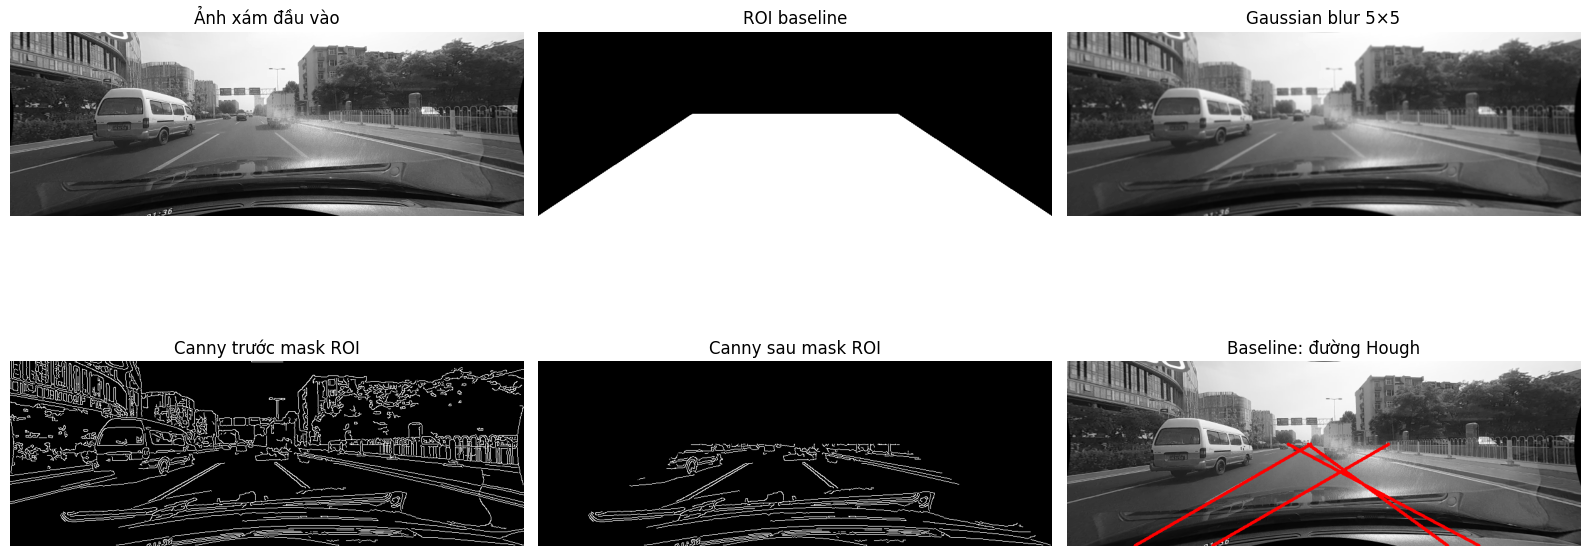

In [3]:
baseline_roi = roi_mask(gray.shape)
baseline_blur = cv2.GaussianBlur(gray, (5, 5), 0)
baseline_canny_all = cv2.Canny(baseline_blur, params.b_lo, params.b_hi) > 0
baseline_edges = baseline_canny_all & baseline_roi
baseline_lines, baseline_debug = run_baseline(gray, params, debug=True)
baseline_result = overlay(item, baseline_lines)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
panels = [
    ('Ảnh xám đầu vào', gray, 'gray'),
    ('ROI baseline', baseline_roi, 'gray'),
    ('Gaussian blur 5×5', baseline_blur, 'gray'),
    ('Canny trước mask ROI', baseline_canny_all, 'gray'),
    ('Canny sau mask ROI', baseline_edges, 'gray'),
    ('Baseline: đường Hough', cv2.cvtColor(baseline_result, cv2.COLOR_BGR2RGB), None),
]
for ax, (title, image, cmap) in zip(axes.flat, panels):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Proposed P: chuẩn hóa cục bộ → Canny tự cài đặt → Hough theo gradient

Ảnh trung gian được lấy từ đúng các hàm đang dùng trong `proposed.py`. Mức xám được chuẩn hóa riêng **chỉ để hiển thị**; đầu vào detector vẫn là mảng gốc của pipeline. Hai accumulator Hough minh họa khác biệt giữa bỏ phiếu mọi hướng và giới hạn hướng theo gradient.

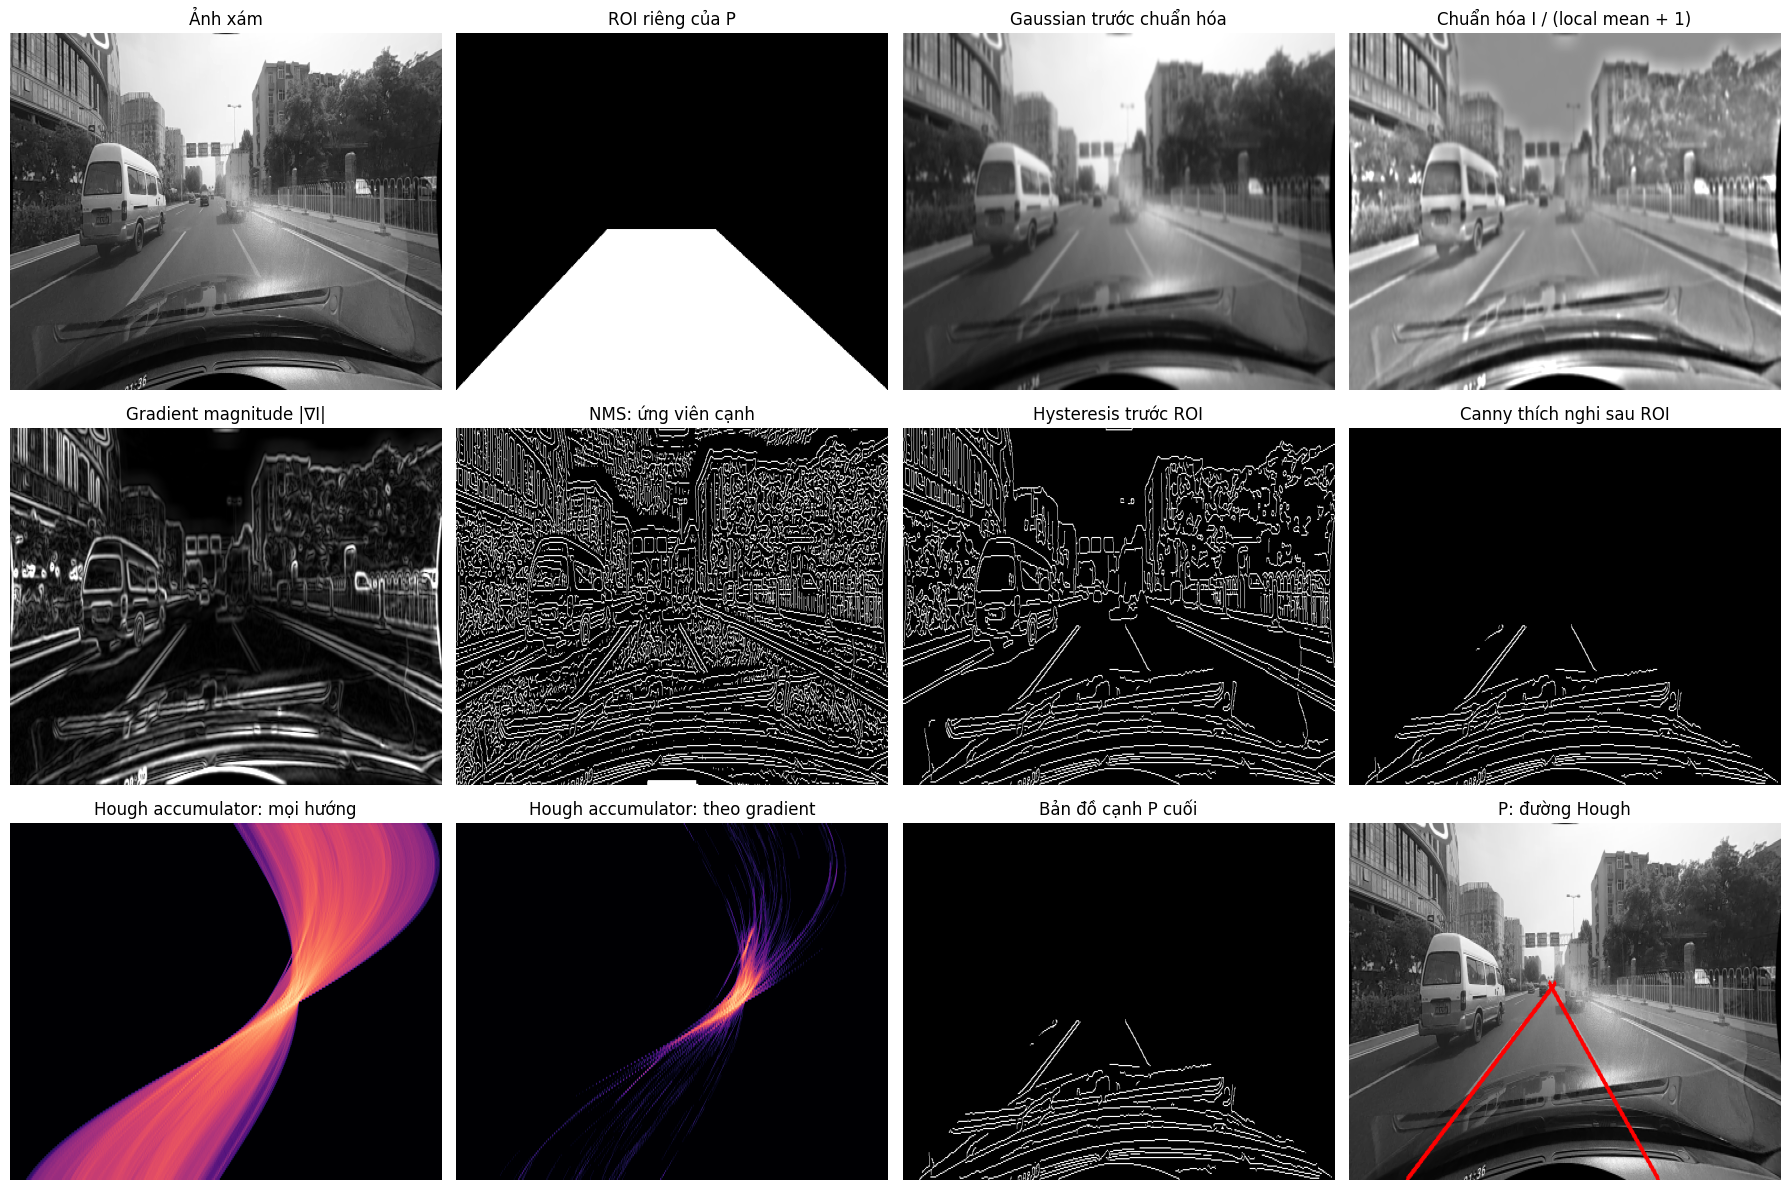

In [4]:
proposed_roi = roi_mask(
    gray.shape,
    top=params.p_roi_top,
    x=(params.p_roi_x_left, params.p_roi_x_right),
)
proposed_blur = gaussian_filter(gray.astype(np.float64), params.sigma) if params.sigma > 0 else gray.astype(np.float64)
normalized = illumination_norm(gray, params.use_norm, params.sigma, params.radius)
gx, gy = sobel(normalized)
magnitude = np.hypot(gx, gy)
nms = non_max_suppression(magnitude, gx, gy)
lo, hi = (0.05, 0.12) if params.use_norm else (10.0, 30.0)
gdir = np.arctan2(gy, gx) % np.pi
edges_before_roi = hysteresis(nms, magnitude, lo * params.thr_scale, hi * params.thr_scale)
proposed_edges = edges_before_roi & proposed_roi
accumulator_all = hough_vote(proposed_edges, gdir, vote=False)
accumulator_gradient = hough_vote(
    proposed_edges, gdir, delta=params.delta, vote=True
)
proposed_lines, proposed_debug = run_proposed(gray, params, debug=True)
proposed_result = overlay(item, proposed_lines)

# Chuẩn hóa ảnh để xem; không dùng các ảnh hiển thị này làm đầu vào tính toán.
def display_gray(image):
    image = np.asarray(image, dtype=np.float64)
    low, high = np.percentile(image, [1, 99])
    return np.clip((image - low) / (high - low + 1e-9), 0, 1)

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
panels = [
    ('Ảnh xám', gray, 'gray'),
    ('ROI riêng của P', proposed_roi, 'gray'),
    ('Gaussian trước chuẩn hóa', display_gray(proposed_blur), 'gray'),
    ('Chuẩn hóa I / (local mean + 1)', display_gray(normalized), 'gray'),
    ('Gradient magnitude |∇I|', display_gray(magnitude), 'gray'),
    ('NMS: ứng viên cạnh', nms, 'gray'),
    ('Hysteresis trước ROI', edges_before_roi, 'gray'),
    ('Canny thích nghi sau ROI', proposed_edges, 'gray'),
    ('Hough accumulator: mọi hướng', np.log1p(accumulator_all).T, 'magma'),
    ('Hough accumulator: theo gradient', np.log1p(accumulator_gradient).T, 'magma'),
    ('Bản đồ cạnh P cuối', proposed_debug['edges'], 'gray'),
    ('P: đường Hough', cv2.cvtColor(proposed_result, cv2.COLOR_BGR2RGB), None),
]
for ax, (title, image, cmap) in zip(axes.flat, panels):
    ax.imshow(image, cmap=cmap, aspect='auto')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. So sánh đầu ra trên cùng ảnh

Đỏ là các đường dự đoán. Baseline và P hiện dùng ROI phát hiện có thể khác nhau (P lấy tham số ROI riêng từ E2), nên khác biệt quan sát được không chỉ đến từ Canny/Hough. Mẫu đơn này không chứng minh P tốt hơn về tổng quát; dùng bảng eval E1/E3 trong báo cáo cho kết luận định lượng.

Đây là minh họa định tính trên một ảnh eval; không tính F1 và không dùng để chọn tham số.


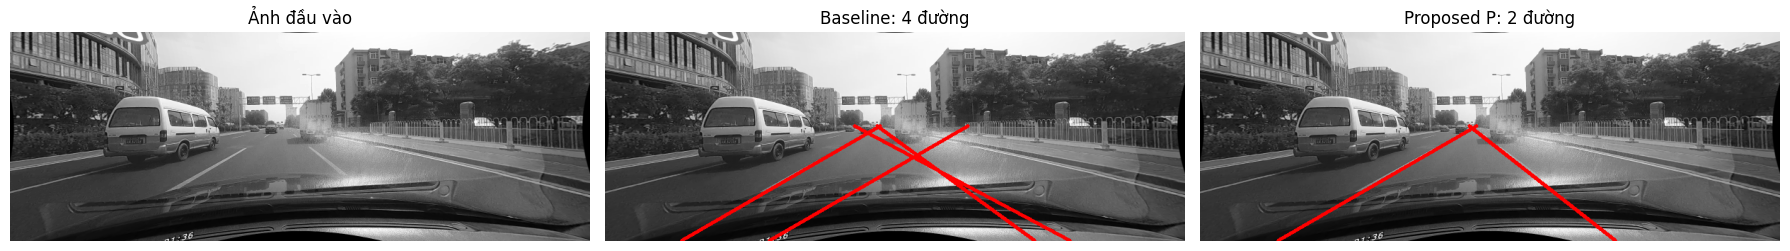

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(gray, cmap='gray')
axes[0].set_title('Ảnh đầu vào')
axes[1].imshow(cv2.cvtColor(baseline_result, cv2.COLOR_BGR2RGB))
axes[1].set_title(f'Baseline: {len(baseline_lines)} đường')
axes[2].imshow(cv2.cvtColor(proposed_result, cv2.COLOR_BGR2RGB))
axes[2].set_title(f'Proposed P: {len(proposed_lines)} đường')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print('Đây là minh họa định tính trên một ảnh eval; không tính F1 và không dùng để chọn tham số.')

## Kết luận và cách chạy

- Baseline: Gaussian blur → Canny ngưỡng cố định → Hough chuẩn.
- P: chuẩn hóa chiếu sáng cục bộ → gradient/NMS/hysteresis → Hough vote theo gradient.
- Notebook không sửa dataset, không chạy lại E1–E4 và không đưa ra đánh giá thống kê từ ảnh mẫu.
- Mở notebook trong VS Code/Jupyter và chọn **Run All** để hiển thị lần lượt tất cả hình. Ví dụ này chỉ dùng để xem các bước xử lý trên ảnh eval; không dùng để chọn tham số hay thay thế thống kê toàn tập.